# Chapitre 3 - Cours 2 : normalisation, jointures et relations plusieurs-à-plusieurs

Le cours 1 a montré le point fort du modèle document : un arbre de relations
un-à-plusieurs lu d'un seul bloc. Ce cours en montre la limite : dès que les
enregistrements **se référencent** entre eux, il faut des identifiants, des jointures, et
choisir entre données **normalisées** et **dénormalisées**. Il couvre les sections
*Normalization, Denormalization, and Joins* (dont *Trade-offs of normalization* et
*Denormalization in the social networking case study*), *Many-to-One and Many-to-Many
Relationships* et *Stars and Snowflakes: Schemas for Analytics*.

**Plan.**

1. Un identifiant ou un texte ? La normalisation.
2. Le compromis lecture/écriture et la cohérence des copies.
3. Relations plusieurs-à-un et plusieurs-à-plusieurs.
4. Dénormaliser à moitié : les timelines et l'hydratation des identifiants.
5. Étoiles et flocons : les schémas de l'analytique.

In [1]:
import json
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

orgs = dm.make_orgs(200, seed=0)
profiles = dm.make_profiles(20_000, seed=0, orgs=orgs)
con = sqlite3.connect(":memory:")
dm.create_relational(con, profiles, orgs)
dm.create_documents(con, profiles)

## 1. Un identifiant ou un texte ? La normalisation (section *Normalization, Denormalization, and Joins*)

Dans nos profils, la région n'est pas stockée en clair (« Lyon, Auvergne-Rhône-Alpes,
France ») mais par un **identifiant** (`"fr:69"`) qui renvoie à une liste normalisée de
régions. Pourquoi ? Proposer une liste déroulante plutôt qu'un champ libre apporte :

- une **orthographe cohérente** d'un profil à l'autre ;
- l'absence d'**ambiguïté** entre lieux homonymes (Valence en France ou en Espagne ?) ;
- une **mise à jour facile** : le nom n'est stocké qu'à un endroit ;
- la **traduction** de l'interface : la liste se localise, pas les profils ;
- une **meilleure recherche** : la liste peut savoir que Lyon est dans le sud-est de la
  France, ce que la chaîne « Lyon » seule ne dit pas.

Stocker un identifiant, c'est **normaliser** : l'information lisible par un humain n'existe
qu'en un exemplaire, tout le reste y renvoie par un identifiant qui n'a de sens que dans
la base. Stocker le texte dans chaque enregistrement, c'est **dénormaliser** : on
duplique l'information. L'identifiant a un avantage décisif : n'ayant **aucun sens pour
un humain**, il n'a jamais besoin de changer, même quand ce qu'il désigne change.

Construisons les deux variantes de la table des profils et mesurons ce que coûte un
changement de nom de région (par exemple après une fusion de régions).

In [2]:
con.executescript("""
DROP TABLE IF EXISTS users_denorm;
CREATE TABLE users_denorm AS
  SELECT u.id, u.first_name, u.last_name, u.headline, r.name AS region_name
    FROM users u JOIN regions r ON r.id = u.region_id;
""")
taille = lambda t, cols: con.execute(f"SELECT SUM({' + '.join(f'LENGTH({c})' for c in cols)}) FROM {t}").fetchone()[0]
n_lyon = con.execute("SELECT COUNT(*) FROM users WHERE region_id = 'fr:69'").fetchone()[0]

def rename(normalise):
    t0 = time.perf_counter()
    if normalise:
        cur = con.execute("UPDATE regions SET name = 'Lyon, Région Lyonnaise, France' WHERE id = 'fr:69'")
    else:
        cur = con.execute("UPDATE users_denorm SET region_name = 'Lyon, Région Lyonnaise, France' "
                          "WHERE region_name = 'Lyon, Auvergne-Rhône-Alpes, France'")
    con.rollback()                                   # on annule pour garder les données intactes
    return cur.rowcount, (time.perf_counter() - t0) * 1e3

(n1, t1), (n2, t2) = rename(True), rename(False)
pd.DataFrame({
    "représentation": ["normalisée (region_id)", "dénormalisée (texte)"],
    "octets pour la région": [taille("users", ["region_id"]) + taille("regions", ["id", "name"]),
                              taille("users_denorm", ["region_name"])],
    "lignes modifiées par le renommage": [n1, n2],
    "temps (ms)": [t1, t2],
})

,représentation,octets pour la région,lignes modifiées par le renommage,temps (ms)
0,normalisée (region_id),102086,1,0.024
1,dénormalisée (texte),551644,1671,1.188


Le renommage touche **une ligne** dans la version normalisée, et les quelque
1 700 profils lyonnais dans la version dénormalisée, qui occupe aussi plusieurs fois plus de place.
Le prix de la normalisation se paie à la lecture : afficher un profil lisible demande
une **jointure** pour résoudre l'identifiant en texte.

In [3]:
SQL_JOIN = """SELECT users.first_name, users.last_name, regions.name
                FROM users JOIN regions ON users.region_id = regions.id
               WHERE users.id = ?"""
print(con.execute(SQL_JOIN, (251,)).fetchone())
for row in con.execute("EXPLAIN QUERY PLAN " + SQL_JOIN, (251,)):
    print("  plan :", row[-1])

('Yanis', 'Michel', 'Nantes, Pays de la Loire, France')
  plan : SEARCH users USING INTEGER PRIMARY KEY (rowid=?)
  plan : SEARCH regions USING INDEX sqlite_autoindex_regions_1 (id=?)


Les bases documents savent stocker des données normalisées ou non, mais on les associe
souvent à la dénormalisation : JSON rend facile l'ajout de champs redondants, et beaucoup
de bases documents gèrent mal les jointures. Sans jointure côté base, l'application la
fait elle-même : lire le document, puis lancer une seconde requête pour résoudre
l'identifiant. MongoDB propose aussi l'opérateur `$lookup` dans son pipeline
d'agrégation ; notre mini-moteur `dm.aggregate` l'implémente.

In [4]:
docs = [json.loads(r[0]) for r in con.execute("SELECT doc FROM profiles WHERE user_id IN (251, 252)")]
regions_coll = [{"_id": k, "name": v} for k, v in dm.REGIONS.items()]
res = dm.aggregate(docs, [
    {"$match": {"user_id": 251}},
    {"$lookup": {"from": "regions", "localField": "region_id", "foreignField": "_id", "as": "region"}},
    {"$project": {"_id": 0, "first_name": 1, "last_name": 1, "region": 1}},
], collections={"regions": regions_coll})
res

[{'first_name': 'Yanis',
  'last_name': 'Michel',
  'region': [{'_id': 'fr:44', 'name': 'Nantes, Pays de la Loire, France'}]}]

> **À retenir.** Normaliser, c'est ranger l'information lisible en un seul exemplaire et
> la référencer par un identifiant sans signification, qui n'a jamais à changer.
> Dénormaliser, c'est dupliquer le texte : lecture sans jointure, mais mises à jour
> multiples et risque d'incohérence.

## 2. Le compromis lecture/écriture et la cohérence des copies (section *Trade-offs of normalization*)

Dans nos CV, l'**organisation** d'un poste existe sous deux formes : son nom (texte
dénormalisé) et son identifiant `org_id` (normalisé). Supposons qu'on veuille afficher le
**logo** de chaque employeur. Dénormalisé, chaque poste porte l'URL du logo ; normalisé,
l'URL n'est stockée qu'une fois dans `organizations`.

Le coût d'un changement de logo dépend alors de la **popularité** de l'organisation. Or
les employeurs suivent une loi de Zipf : quelques géants, une longue traîne.

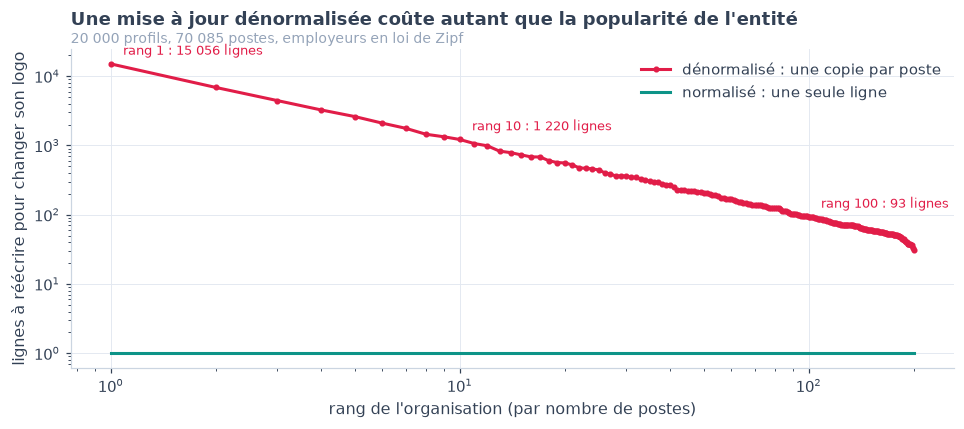

In [5]:
par_org = (pd.read_sql("SELECT org_id, COUNT(*) AS postes FROM positions GROUP BY org_id", con)
           .sort_values("postes", ascending=False).reset_index(drop=True))
par_org["rang"] = np.arange(1, len(par_org) + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.loglog(par_org.rang, par_org.postes, marker="o", ms=3, color=ROSE, label="dénormalisé : une copie par poste")
ax.loglog(par_org.rang, np.ones(len(par_org)), color=TEAL, lw=2, label="normalisé : une seule ligne")
for r in [1, 10, 100]:
    v = par_org.postes[r - 1]
    ax.annotate(f"rang {r} : {fmt(v)} lignes", (r, v), (8, 6), textcoords="offset points", fontsize=8.5, color=ROSE)
ax.set_xlabel("rang de l'organisation (par nombre de postes)")
ax.set_ylabel("lignes à réécrire pour changer son logo")
ax.set_title("Une mise à jour dénormalisée coûte autant que la popularité de l'entité")
subtitle(ax, f"{fmt(len(profiles))} profils, {fmt(par_org.postes.sum())} postes, employeurs en loi de Zipf")
ax.legend(); plt.tight_layout(); plt.show()

Mesurons aussi l'autre côté du compromis, la **lecture** : afficher les postes d'un
profil avec le nom et le logo de l'employeur, avec ou sans jointure.

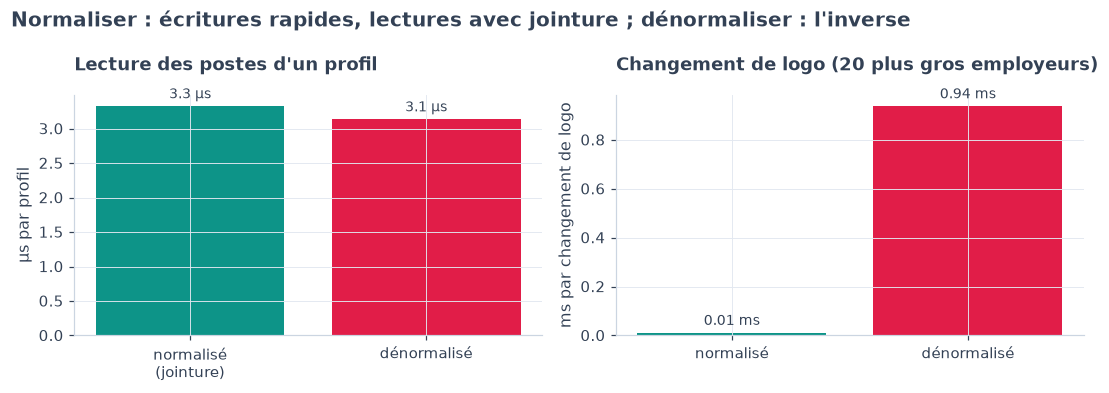

In [6]:
con.executescript("""
DROP TABLE IF EXISTS positions_denorm;
CREATE TABLE positions_denorm AS
  SELECT p.id, p.user_id, p.job_title, o.name AS org_name, o.logo_url, p.start, p."end"
    FROM positions p JOIN organizations o ON o.id = p.org_id;
CREATE INDEX pd_user ON positions_denorm (user_id);
CREATE INDEX pd_id ON positions_denorm (id);
CREATE INDEX pd_org ON positions_denorm (org_name);
""")
def bench(sql, n=3000):
    ids = rng.integers(1, len(profiles) + 1, n).tolist()
    t0 = time.perf_counter()
    for u in ids:
        con.execute(sql, (u,)).fetchall()
    return (time.perf_counter() - t0) / n * 1e6

lect_norm = bench("SELECT p.job_title, o.name, o.logo_url FROM positions p JOIN organizations o ON o.id = p.org_id WHERE p.user_id = ?")
lect_denorm = bench("SELECT job_title, org_name, logo_url FROM positions_denorm WHERE user_id = ?")
ecr = {}
for label, sql in [("normalisé", "UPDATE organizations SET logo_url = ? WHERE id = ?"),
                   ("dénormalisé", "UPDATE positions_denorm SET logo_url = ? WHERE org_name = (SELECT name FROM organizations WHERE id = ?)")]:
    t0 = time.perf_counter()
    for oid in par_org.org_id[:20]:
        con.execute(sql, ("/logos/v2.png", int(oid)))
    con.rollback()
    ecr[label] = (time.perf_counter() - t0) / 20 * 1e3

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(["normalisé\n(jointure)", "dénormalisé"], [lect_norm, lect_denorm], color=[TEAL, ROSE])
annotate_bars(axes[0], "{:.1f} µs"); axes[0].set_ylabel("µs par profil"); axes[0].set_title("Lecture des postes d'un profil")
axes[1].bar(["normalisé", "dénormalisé"], [ecr["normalisé"], ecr["dénormalisé"]], color=[TEAL, ROSE])
annotate_bars(axes[1], "{:.2f} ms"); axes[1].set_ylabel("ms par changement de logo")
axes[1].set_title("Changement de logo (20 plus gros employeurs)")
finish(fig, "Normaliser : écritures rapides, lectures avec jointure ; dénormaliser : l'inverse")

Sur une base locale, la lecture avec jointure n'est qu'à peine plus lente (une fraction
de microseconde par profil, car la table des organisations est petite et tient en
mémoire) ; la mise à jour dénormalisée, elle, est des centaines de fois plus lente, car
elle parcourt et réécrit toutes les copies. C'est le principe général énoncé par le
livre : des données normalisées sont **plus rapides à écrire** (une seule copie) et **plus
lentes à lire** (jointures) ; des données dénormalisées, l'inverse, avec en prime plus
d'espace disque. On peut voir la dénormalisation comme une forme de **donnée dérivée** : il faut un processus pour tenir les copies à jour.

**Et si le processus tombe en panne au milieu ?** Mettre à jour plusieurs copies, c'est
faire plusieurs écritures. Si le processus s'arrête entre deux, certaines copies portent
l'ancienne valeur, d'autres la nouvelle. Simulons un renommage de l'employeur le plus
populaire, interrompu à un instant aléatoire, avec et sans **transaction atomique**.

In [7]:
top = int(par_org.org_id[0])
top_name = con.execute("SELECT name FROM organizations WHERE id = ?", (top,)).fetchone()[0]
ids_top = [r[0] for r in con.execute("SELECT id FROM positions_denorm WHERE org_name = ?", (top_name,))]

def rename_with_crash(atomic, crash_after):
    """Renomme copie par copie ; une exception simule l'arrêt du processus."""
    try:
        if atomic:
            con.execute("BEGIN")
        for k, pid in enumerate(ids_top):
            if k == crash_after:
                raise RuntimeError("panne du processus")
            con.execute("UPDATE positions_denorm SET org_name = ? WHERE id = ?", (top_name + " SA", pid))
        con.commit()
    except RuntimeError:
        if atomic:
            con.rollback()                               # la base annule toute la transaction
        else:
            con.commit()                                 # sans transaction, le travail fait reste fait
    n_old = con.execute("SELECT COUNT(*) FROM positions_denorm WHERE org_name = ?", (top_name,)).fetchone()[0]
    n_new = con.execute("SELECT COUNT(*) FROM positions_denorm WHERE org_name = ?", (top_name + " SA",)).fetchone()[0]
    con.execute("UPDATE positions_denorm SET org_name = ? WHERE org_name = ?", (top_name, top_name + " SA"))
    con.commit()
    return n_old, n_new

con.isolation_level = None                               # contrôle explicite des transactions
crashes = sorted(rng.integers(1, len(ids_top), 8).tolist())
res = pd.DataFrame([(c, *rename_with_crash(False, c), *rename_with_crash(True, c)) for c in crashes],
                   columns=["panne après", "sans tx : ancien nom", "sans tx : nouveau nom",
                            "avec tx : ancien nom", "avec tx : nouveau nom"])
con.isolation_level = ""
res

,panne après,sans tx : ancien nom,sans tx : nouveau nom,avec tx : ancien nom,avec tx : nouveau nom
0,2476,12580,2476,15056,0
1,2614,12442,2614,15056,0
2,6937,8119,6937,15056,0
3,8069,6987,8069,15056,0
4,11969,3087,11969,15056,0
5,12385,2671,12385,15056,0
6,13377,1679,13377,15056,0
7,14548,508,14548,15056,0


Sans transaction, chaque panne laisse la base dans un état **mixte** : le même employeur
porte deux noms, et rien ne permet de savoir lequel est le bon. Avec une transaction
atomique, la base revient entièrement à l'état initial. C'est l'**atomicité** du chapitre
8 ; toutes les bases documents ne l'offrent pas pour une écriture qui
touche **plusieurs documents**.

**Quand normaliser ?** Le livre conseille la normalisation pour les systèmes
transactionnels, où lectures et écritures doivent être rapides, et pour les systèmes de
taille modeste, où le coût des jointures reste acceptable. Les systèmes analytiques, qui
écrivent par lots et lisent beaucoup, s'accommodent mieux de la dénormalisation. À très
grande échelle, le coût des jointures peut devenir un problème.

> **À retenir.** Normalisé : écriture en un point, lecture avec jointure. Dénormalisé :
> lecture directe, mais chaque mise à jour coûte autant que le nombre de copies (donc la
> popularité de l'entité) et une panne au milieu laisse des copies incohérentes, sauf
> transaction atomique.

## 3. Relations plusieurs-à-un et plusieurs-à-plusieurs (section *Many-to-One and Many-to-Many Relationships*)

Les postes d'un CV sont une relation **un-à-plusieurs** (un profil, plusieurs postes ;
chaque poste appartient à un seul profil). La région est une relation **plusieurs-à-un**
(beaucoup de profils dans la même région, une seule région par profil). Dès que les
organisations deviennent des entités référencées par identifiant, on obtient une
relation **plusieurs-à-plusieurs** : une personne a travaillé pour plusieurs
organisations, une organisation a eu plusieurs employés.

En relationnel, on la représente par une **table d'association** (ou table de jointure) :
ici `positions`, dont chaque ligne associe un `user_id` à un `org_id`. Une telle
relation s'interroge dans **les deux sens** : les employeurs d'une personne, et les
anciens employés d'une organisation. Il faut pour cela un **index secondaire** sur chacune
des deux colonnes ; observons le plan de requête avant et après la création de l'index
sur `org_id`.

In [8]:
Q_PERSONNES = "SELECT DISTINCT u.first_name, u.last_name FROM positions p JOIN users u ON u.id = p.user_id WHERE p.org_id = ?"
def plan(sql, args):
    return " | ".join(r[-1] for r in con.execute("EXPLAIN QUERY PLAN " + sql, args))
oid = int(par_org.org_id[50])
avant = plan(Q_PERSONNES, (oid,))
t0 = time.perf_counter(); [con.execute(Q_PERSONNES, (int(o),)).fetchall() for o in par_org.org_id[:100]]
t_sans = (time.perf_counter() - t0) / 100 * 1e3
con.execute("CREATE INDEX positions_org ON positions (org_id)")
t0 = time.perf_counter(); [con.execute(Q_PERSONNES, (int(o),)).fetchall() for o in par_org.org_id[:100]]
t_avec = (time.perf_counter() - t0) / 100 * 1e3
pd.DataFrame({"index sur org_id": ["non", "oui"], "plan": [avant, plan(Q_PERSONNES, (oid,))],
              "ms par requête": [t_sans, t_avec]})

,index sur org_id,plan,ms par requête
0,non,SCAN p | SEARCH u USING INTEGER PRIMARY KEY (rowid=?) | USE TEMP B-TREE FOR DISTINCT,1.513
1,oui,SEARCH p USING INDEX positions_org (org_id=?) | SEARCH u USING INTEGER PRIMARY KEY (ro...,0.320


Sans index, SQLite doit **parcourir toute la table** `positions` pour trouver les postes
d'une organisation ; avec l'index, il y **cherche** directement. La relation stockée une
seule fois (normalisée) est interrogeable efficacement dans les deux sens, à condition
d'indexer les deux colonnes.

**Dans le modèle document**, les relations plusieurs-à-un et plusieurs-à-plusieurs ne
tiennent pas dans un document autonome. Une représentation possible : ce qui forme un
arbre reste dans le document du profil, et les organisations deviennent des documents à
part, **référencés par identifiant**.

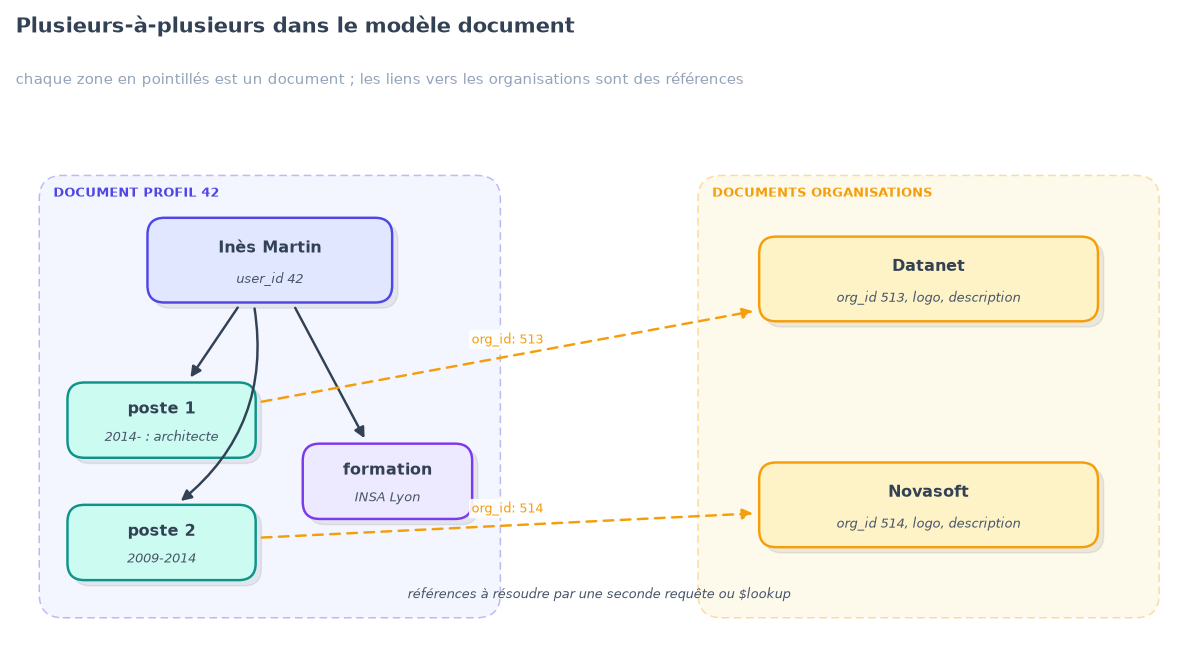

In [9]:
d = Diagram(12.5, 5.8, title="Plusieurs-à-plusieurs dans le modèle document",
            subtitle="chaque zone en pointillés est un document ; les liens vers les organisations sont des références")
d.group(0.3, 0.3, 5.2, 5.0, "document profil 42", color=INDIGO)
d.box("p42", 2.75, 4.1, "Inès Martin", sub="user_id 42", color=INDIGO, w=2.6)
d.box("pa", 1.6, 2.4, "poste 1", sub="2014- : architecte", color=TEAL, w=2.0, h=0.8)
d.box("pb", 1.6, 1.1, "poste 2", sub="2009-2014", color=TEAL, w=2.0, h=0.8)
d.box("ed", 4.0, 1.75, "formation", sub="INSA Lyon", color=VIOLET, w=1.8, h=0.8)
d.arrow("p42", "pa"); d.arrow("p42", "ed")
d.arrow("p42", "pb", rad=-0.3)
d.group(7.3, 0.3, 12.2, 5.0, "documents organisations", color=AMBER)
d.box("o1", 9.75, 3.9, "Datanet", sub="org_id 513, logo, description", color=AMBER, w=3.6)
d.box("o2", 9.75, 1.5, "Novasoft", sub="org_id 514, logo, description", color=AMBER, w=3.6)
d.arrow("pa", "o1", "org_id: 513", style="dashed", color=AMBER)
d.arrow("pb", "o2", "org_id: 514", style="dashed", color=AMBER)
d.note(6.25, 0.55, "références à résoudre par une seconde requête ou $lookup", fontsize=8.5)
d.show()

Pour interroger la relation dans les deux sens, on est tenté de stocker les références
**des deux côtés** : chaque profil liste ses `org_id`, et chaque organisation la liste des
profils qui la mentionnent. C'est une **dénormalisation** : la même relation existe en deux
endroits, qui peuvent diverger. Simulons 10 000 ajouts de postes, chacun écrivant deux
documents l'un après l'autre, avec une probabilité de panne de 0,5 % entre les deux.

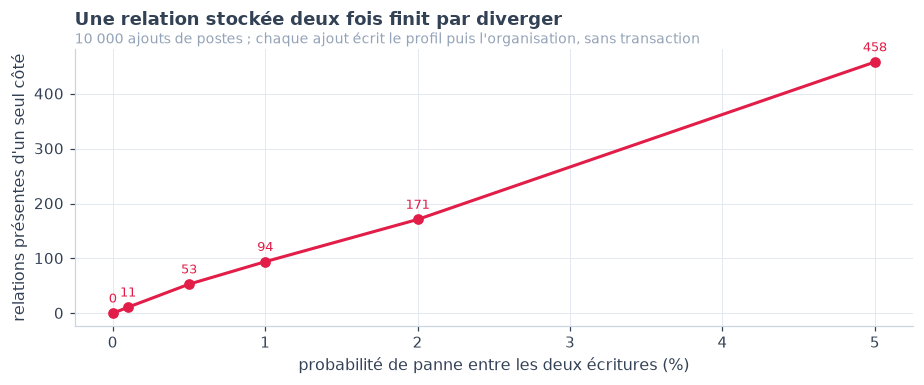

In [10]:
def simulate_bidirectional(n_ops, p_crash, seed=0):
    r = np.random.default_rng(seed)
    user_orgs, org_users = {}, {}
    for _ in range(n_ops):
        u, o = int(r.integers(1, 2001)), int(r.choice(par_org.org_id[:50]))
        user_orgs.setdefault(u, set()).add(o)          # écriture 1 : document du profil
        if r.random() < p_crash:
            continue                                    # panne : l'écriture 2 n'a jamais lieu
        org_users.setdefault(o, set()).add(u)           # écriture 2 : document de l'organisation
    pairs_u = {(u, o) for u, os in user_orgs.items() for o in os}
    pairs_o = {(u, o) for o, us in org_users.items() for u in us}
    return len(pairs_u - pairs_o), len(pairs_u)

ps = [0.0, 0.001, 0.005, 0.01, 0.02, 0.05]
inco = [simulate_bidirectional(10_000, p)[0] for p in ps]
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot([p * 100 for p in ps], inco, marker="o", color=ROSE)
for p, v in zip(ps, inco):
    ax.annotate(fmt(v), (p * 100, v), (0, 7), textcoords="offset points", ha="center", fontsize=8.5, color=ROSE)
ax.set_xlabel("probabilité de panne entre les deux écritures (%)")
ax.set_ylabel("relations présentes d'un seul côté")
ax.set_title("Une relation stockée deux fois finit par diverger")
subtitle(ax, "10 000 ajouts de postes ; chaque ajout écrit le profil puis l'organisation, sans transaction")
plt.tight_layout(); plt.show()

La représentation **normalisée** stocke la relation en un seul endroit et compte sur des
**index secondaires** (chapitre 4) pour l'interroger dans les deux sens. Dans
le modèle document, il faut pour cela indexer le champ `org_id` des objets **à
l'intérieur** du tableau `positions` : beaucoup de bases documents, et les bases
relationnelles avec support JSON, savent indexer ainsi des valeurs imbriquées
(PostgreSQL le fait avec un index GIN, voir le lab). SQLite, lui, ne sait pas indexer les
éléments d'un tableau JSON : la requête doit déplier tous les documents.

In [11]:
Q_DOC = """SELECT p.user_id FROM profiles p, json_each(p.doc, '$.positions') AS j
            WHERE j.value ->> 'org_id' = ?"""
Q_TAB = "SELECT user_id FROM positions WHERE org_id = ?"
assert sorted(set(r[0] for r in con.execute(Q_DOC, (oid,)))) == sorted(set(r[0] for r in con.execute(Q_TAB, (oid,))))
t0 = time.perf_counter(); [con.execute(Q_DOC, (int(o),)).fetchall() for o in par_org.org_id[:10]]; t_doc = (time.perf_counter() - t0) / 10 * 1e3
t0 = time.perf_counter(); [con.execute(Q_TAB, (int(o),)).fetchall() for o in par_org.org_id[:10]]; t_tab = (time.perf_counter() - t0) / 10 * 1e3
print(f"anciens employés d'une organisation : documents dépliés {t_doc:.1f} ms ; table indexée {t_tab:.2f} ms ; "
      f"rapport {t_doc / t_tab:.0f}")

anciens employés d'une organisation : documents dépliés 52.7 ms ; table indexée 1.35 ms ; rapport 39


> **À retenir.** Plusieurs-à-un et plusieurs-à-plusieurs appellent une représentation
> **normalisée** : une table d'association indexée sur ses deux colonnes, ou des
> références entre documents avec un index sur les valeurs imbriquées. Stocker la
> relation des deux côtés est une dénormalisation qui diverge à la première panne.

## 4. Dénormaliser à moitié : les timelines et l'hydratation (section *Denormalization in the social networking case study*)

Le chapitre 2 a comparé deux représentations des timelines d'un réseau
social : normalisée (jointure entre `posts` et `follows` à chaque lecture) et
dénormalisée (timelines **matérialisées**, mises à jour par fan-out). La timeline
matérialisée est un **cache du résultat de la jointure**, et le fan-out est le processus
qui garde cette copie cohérente.

Le livre précise un détail instructif : chez X (ex-Twitter), une entrée de timeline ne
contient **pas** le texte du message, seulement son identifiant, celui de l'auteur et
quelques drapeaux (partage, réponse). À l'affichage, le service doit donc encore
**hydrater** ces identifiants : chercher le contenu du message (et ses compteurs de
« j'aime » et de réponses), puis le profil de l'auteur (nom, photo). C'est une jointure
faite **dans le code applicatif**.

Pourquoi ne pas tout dénormaliser ? Parce que ces informations **changent vite** : le
compteur de « j'aime » d'un message populaire bouge plusieurs fois par seconde, et un
auteur peut changer de photo. Simulons une heure d'activité sur un petit réseau et
comptons les écritures que demanderait chaque stratégie.

In [12]:
n_users, n_posts_h = 50_000, 20_000
followers = np.minimum((rng.pareto(1.2, n_users) + 1) * 20, n_users - 1).astype(int)   # abonnés par compte
authors = rng.integers(0, n_users, n_posts_h)
likes = rng.poisson(5 + 0.05 * followers[authors])                                     # j'aime par message
photo_changes = rng.binomial(1, 0.002, n_users)                                         # 0,2 % changent de photo

ecritures = pd.DataFrame({
    "stratégie": ["identifiants seuls (hydratation)", "texte et compteurs dénormalisés"],
    "fan-out des nouveaux messages": [followers[authors].sum(), followers[authors].sum()],
    "mises à jour des compteurs": [likes.sum(), (likes * followers[authors]).sum()],
    "changements de photo": [photo_changes.sum(),
                             sum(followers[a] * (authors == a).sum() for a in np.flatnonzero(photo_changes))],
})
ecritures["total"] = ecritures.iloc[:, 1:].sum(axis=1)
ecritures.set_index("stratégie").T.map(fmt)

stratégie,identifiants seuls (hydratation),texte et compteurs dénormalisés
fan-out des nouveaux messages,1 951 692,1 951 692
mises à jour des compteurs,197 590,601 968 313
changements de photo,112,1 761
total,2 149 394,603 921 766


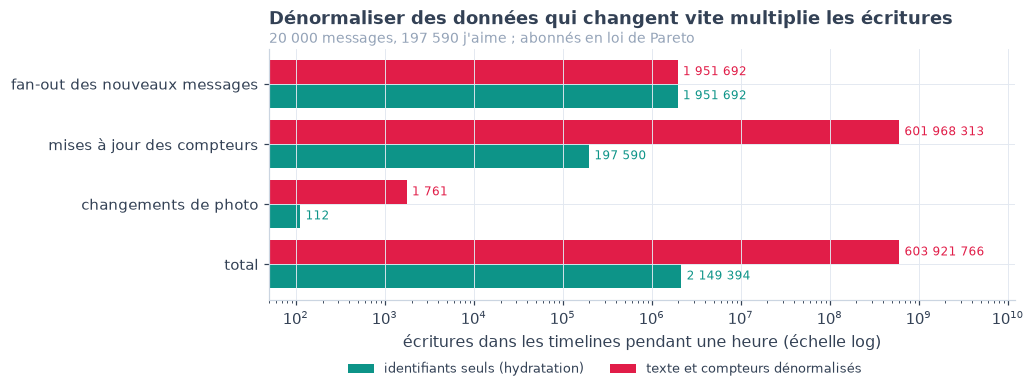

In [13]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
cols = ["fan-out des nouveaux messages", "mises à jour des compteurs", "changements de photo", "total"]
y = np.arange(len(cols))
for k, (col, lab) in enumerate([(TEAL, ecritures["stratégie"][0]), (ROSE, ecritures["stratégie"][1])]):
    vals = ecritures.loc[k, cols].to_numpy(dtype=float)
    ax.barh(y + (0.2 if k == 0 else -0.2), vals, 0.4, color=col, label=lab)
    for yy, v in zip(y, vals):
        ax.text(v * 1.15, yy + (0.2 if k == 0 else -0.2), fmt(v), va="center", fontsize=8, color=col)
ax.set_xscale("log"); ax.set_yticks(y, cols); ax.invert_yaxis()
ax.set_xlim(50, ecritures["total"].max() * 20)
ax.set_xlabel("écritures dans les timelines pendant une heure (échelle log)")
ax.set_title("Dénormaliser des données qui changent vite multiplie les écritures")
subtitle(ax, f"{fmt(n_posts_h)} messages, {fmt(likes.sum())} j'aime ; abonnés en loi de Pareto")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.2), ncol=2, fontsize=8.5); plt.tight_layout(); plt.show()

Recopier les compteurs dans chaque timeline transformerait **chaque « j'aime »** en
autant d'écritures que l'auteur a d'abonnés : le total explose. L'hydratation, elle,
coûte à la lecture deux recherches par identifiant, faciles à paralléliser et
**indépendantes** du nombre d'abonnés ou d'abonnements. Le livre en tire une leçon : faire
des jointures à la lecture n'empêche pas de construire un service rapide et scalable.
La bonne solution **dénormalise certaines choses** (la liste des identifiants de la
timeline) **et en laisse d'autres normalisées** (le contenu, les compteurs, les profils),
selon la fréquence des changements et le coût des lectures et des écritures.

> **À retenir.** Normaliser ou dénormaliser n'est ni bon ni mauvais en soi : c'est un
> compromis entre coût des lectures, coût des écritures et effort d'implémentation. On
> dénormalise ce qui change rarement et coûte cher à joindre, on garde normalisé ce qui
> change souvent.

## 5. Étoiles et flocons : les schémas de l'analytique (section *Stars and Snowflakes: Schemas for Analytics*)

Les **entrepôts de données** sont presque toujours relationnels, et leurs tables suivent
quelques conventions bien établies : **schéma en étoile**, **schéma en flocon**,
modélisation dimensionnelle, ou **une grande table** (*one big table*, OBT). Des
processus ETL traduisent les données des systèmes opérationnels vers ce schéma.

Au centre de l'étoile se trouve la **table de faits** : chaque ligne est un **événement**
daté (ici, la vente d'un livre dans une librairie d'une chaîne). On garde les faits
individuels pour garder toute la souplesse d'analyse, ce qui rend cette table immense.
Certaines colonnes sont des **attributs** (prix, coût d'achat) ; les autres sont des clés
étrangères vers des **tables de dimensions**, qui décrivent le qui, quoi, où, quand,
comment et pourquoi de l'événement. Même la date est une dimension, pour pouvoir y
attacher des informations comme les jours fériés.

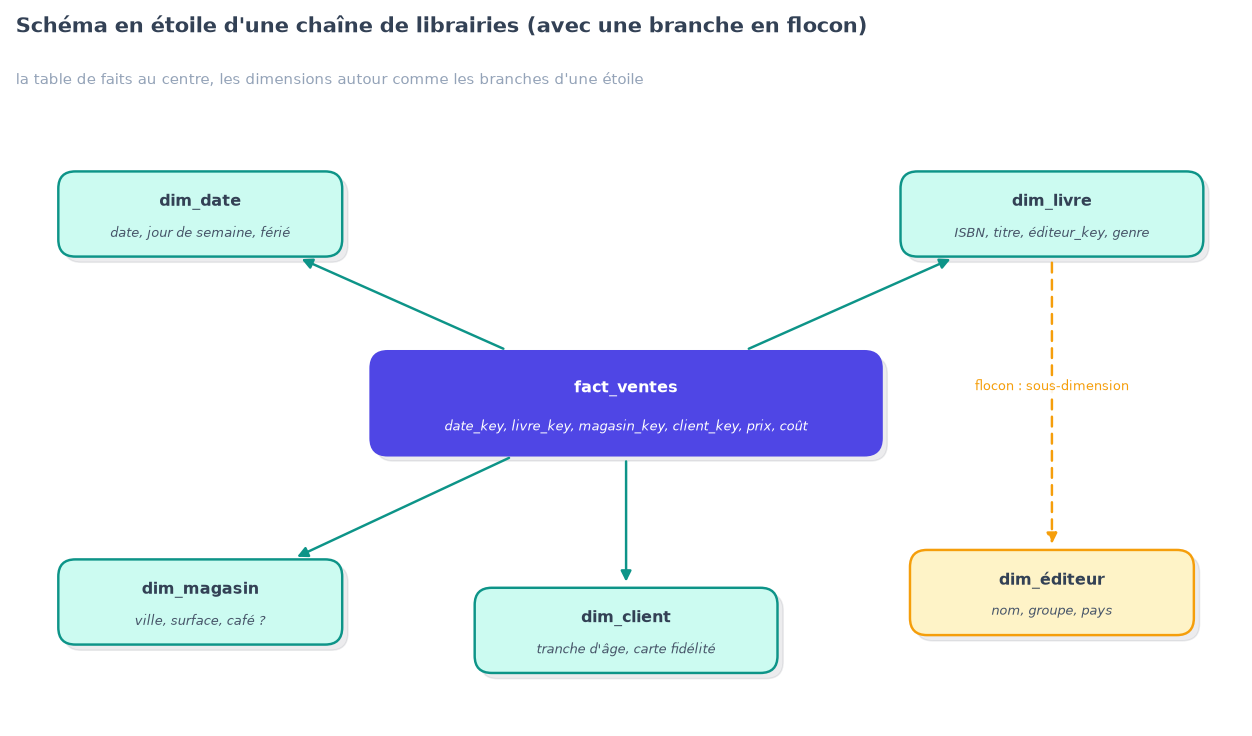

In [14]:
d = Diagram(13, 6.6, title="Schéma en étoile d'une chaîne de librairies (avec une branche en flocon)",
            subtitle="la table de faits au centre, les dimensions autour comme les branches d'une étoile")
d.box("fact", 6.5, 3.4, "fact_ventes", sub="date_key, livre_key, magasin_key, client_key, prix, coût",
      color=INDIGO, w=5.4, h=1.1, filled=True)
d.box("date", 2.0, 5.4, "dim_date", sub="date, jour de semaine, férié", color=TEAL, w=3.0)
d.box("livre", 11.0, 5.4, "dim_livre", sub="ISBN, titre, éditeur_key, genre", color=TEAL, w=3.2)
d.box("mag", 2.0, 1.3, "dim_magasin", sub="ville, surface, café ?", color=TEAL, w=3.0)
d.box("cli", 6.5, 1.0, "dim_client", sub="tranche d'âge, carte fidélité", color=TEAL, w=3.2)
d.box("edit", 11.0, 1.4, "dim_éditeur", sub="nom, groupe, pays", color=AMBER, w=3.0)
for k in ["date", "livre", "mag", "cli"]:
    d.arrow("fact", k, color=TEAL)
d.arrow("livre", "edit", "flocon : sous-dimension", color=AMBER, style="dashed")
d.show()

Construisons cet entrepôt miniature (200 000 ventes) en trois variantes et comparons-les
sur une requête typique : le chiffre d'affaires par genre et par jour férié ou non.

- **étoile** : le genre et l'éditeur sont des colonnes texte de `dim_livre` ;
- **flocon** : `dim_livre` référence une sous-dimension `dim_genre` (plus normalisé,
  une jointure de plus) ;
- **OBT** : toutes les colonnes des dimensions recopiées dans la table de faits (la
  jointure est précalculée).

In [15]:
w = sqlite3.connect(":memory:")
n_livres, n_mag, n_jours, n_ventes = 5000, 40, 730, 200_000
genres = ["roman", "polar", "BD", "jeunesse", "essai", "cuisine", "voyage", "SF"]
w.execute("CREATE TABLE dim_genre (genre_key INTEGER PRIMARY KEY, genre TEXT, rayon TEXT)")
w.executemany("INSERT INTO dim_genre VALUES (?, ?, ?)", [(i, g, "rayon " + g[0].upper()) for i, g in enumerate(genres)])
g_of = rng.integers(0, len(genres), n_livres)
w.execute("CREATE TABLE dim_livre_flocon (livre_key INTEGER PRIMARY KEY, isbn TEXT, titre TEXT, genre_key INTEGER)")
w.executemany("INSERT INTO dim_livre_flocon VALUES (?, ?, ?, ?)",
              [(i, f"978-{i:09d}", f"Titre {i}", int(g_of[i])) for i in range(n_livres)])
w.execute("CREATE TABLE dim_livre AS SELECT l.livre_key, l.isbn, l.titre, g.genre, g.rayon "
          "FROM dim_livre_flocon l JOIN dim_genre g USING (genre_key)")
w.execute("CREATE TABLE dim_date (date_key INTEGER PRIMARY KEY, jour TEXT, ferie INTEGER)")
feries = set(rng.choice(n_jours, 22, replace=False).tolist())
w.executemany("INSERT INTO dim_date VALUES (?, ?, ?)", [(k, f"J{k}", int(k in feries)) for k in range(n_jours)])
w.execute("CREATE TABLE fact_ventes (date_key INTEGER, livre_key INTEGER, magasin_key INTEGER, prix REAL, cout REAL)")
lk = rng.zipf(1.3, n_ventes) % n_livres
w.executemany("INSERT INTO fact_ventes VALUES (?, ?, ?, ?, ?)",
              zip(rng.integers(0, n_jours, n_ventes).tolist(), lk.tolist(), rng.integers(0, n_mag, n_ventes).tolist(),
                  np.round(rng.uniform(6, 35, n_ventes), 2).tolist(), np.round(rng.uniform(3, 20, n_ventes), 2).tolist()))
w.execute("CREATE TABLE obt AS SELECT f.*, l.isbn, l.titre, l.genre, l.rayon, d.jour, d.ferie "
          "FROM fact_ventes f JOIN dim_livre l USING (livre_key) JOIN dim_date d USING (date_key)")

REQ = {
    "étoile": """SELECT l.genre, d.ferie, SUM(f.prix) FROM fact_ventes f
                 JOIN dim_livre l USING (livre_key) JOIN dim_date d USING (date_key) GROUP BY 1, 2""",
    "flocon": """SELECT g.genre, d.ferie, SUM(f.prix) FROM fact_ventes f
                 JOIN dim_livre_flocon l USING (livre_key) JOIN dim_genre g USING (genre_key)
                 JOIN dim_date d USING (date_key) GROUP BY 1, 2""",
    "OBT": "SELECT genre, ferie, SUM(prix) FROM obt GROUP BY 1, 2",
}
res, out = {}, []
for k, sql in REQ.items():
    t0 = time.perf_counter(); res[k] = sorted(w.execute(sql).fetchall()); dt = time.perf_counter() - t0
    out.append({"schéma": k, "jointures": sql.count("JOIN"), "temps (ms)": dt * 1e3})
assert all(np.allclose([r[2] for r in res[k]], [r[2] for r in res["étoile"]]) for k in res)
w.commit(); w.execute("VACUUM")
octets = {t: w.execute("SELECT SUM(pgsize) FROM dbstat WHERE name = ?", (t,)).fetchone()[0]
          for t in ["fact_ventes", "dim_livre", "dim_livre_flocon", "dim_genre", "dim_date", "obt"]}
taille_schema = {"étoile": octets["fact_ventes"] + octets["dim_livre"] + octets["dim_date"],
                 "flocon": octets["fact_ventes"] + octets["dim_livre_flocon"] + octets["dim_genre"] + octets["dim_date"],
                 "OBT": octets["obt"]}
out = pd.DataFrame(out)
out["taille (Mo)"] = [taille_schema[k] / 1e6 for k in out["schéma"]]
out

,schéma,jointures,temps (ms),taille (Mo)
0,étoile,2,101.552,6.619
1,flocon,3,100.172,6.554
2,OBT,0,59.746,14.885


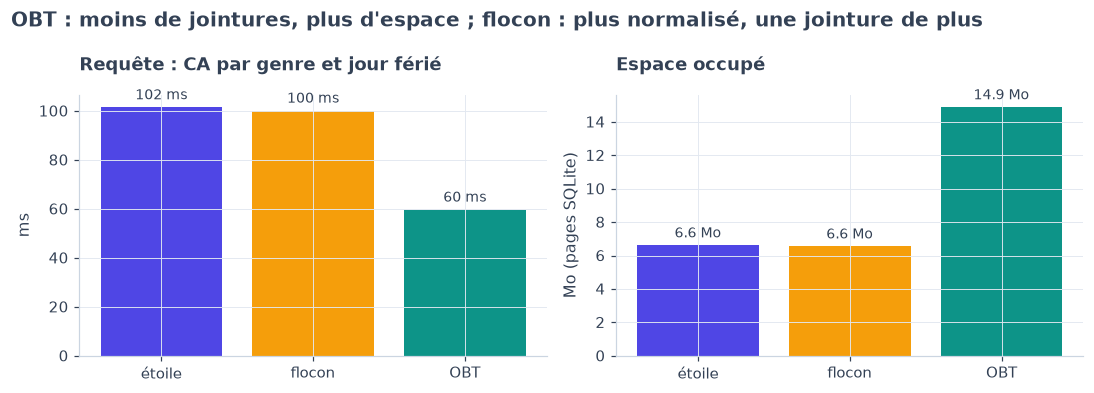

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(out["schéma"], out["temps (ms)"], color=[INDIGO, AMBER, TEAL]); annotate_bars(axes[0], "{:.0f} ms")
axes[0].set_ylabel("ms"); axes[0].set_title("Requête : CA par genre et jour férié")
axes[1].bar(out["schéma"], out["taille (Mo)"], color=[INDIGO, AMBER, TEAL]); annotate_bars(axes[1], "{:.1f} Mo")
axes[1].set_ylabel("Mo (pages SQLite)"); axes[1].set_title("Espace occupé")
finish(fig, "OBT : moins de jointures, plus d'espace ; flocon : plus normalisé, une jointure de plus")

Les trois schémas donnent le même résultat. L'OBT évite toute jointure et répond le plus
vite, au prix d'une table nettement plus grosse (chaque vente recopie le titre, le genre,
le rayon...) ; le flocon, plus normalisé, ajoute une jointure. Le livre note que les
analystes préfèrent souvent l'étoile, plus simple à manipuler que le flocon. En
analytique, la dénormalisation pose peu de problèmes : les faits sont un **historique**
qui ne change pas (hormis la correction d'erreurs), donc les soucis de cohérence et de
coût d'écriture vus en section 2 disparaissent presque. Les tables réelles sont aussi
**larges** (souvent plus de cent colonnes) : c'est ce qui motive le stockage en colonnes
du chapitre 4.

Remarquez enfin qu'un schéma en étoile est fait presque uniquement de relations
**plusieurs-à-un** (beaucoup de ventes pour un livre, un magasin, un jour). Une commande
de plusieurs livres n'y est pas représentée comme telle : elle devient plusieurs lignes de
faits qui partagent le même client, le même magasin et le même horodatage.

> **À retenir.** Un entrepôt range ses événements dans une immense table de faits
> entourée de dimensions (étoile), éventuellement découpées en sous-dimensions (flocon)
> ou au contraire repliées dans la table de faits (OBT). En analytique, la
> dénormalisation est sans danger car les faits ne changent pas.

## Synthèse

- **Normaliser** : l'information lisible en un seul exemplaire, référencée par un
  identifiant sans signification. Écritures en un point, lectures avec **jointure**.
- **Dénormaliser** : dupliquer pour lire sans jointure ; chaque mise à jour coûte autant
  que le nombre de copies, et une panne en cours de route laisse des copies incohérentes
  sans transaction atomique (chapitre 8).
- Les relations **plusieurs-à-un** et **plusieurs-à-plusieurs** appellent la
  normalisation : table d'association indexée dans les deux sens (chapitre
  4), ou références entre documents.
- La meilleure architecture dénormalise une partie seulement (timelines d'identifiants hydratés à la lecture) ; en analytique, étoiles, flocons et OBT dénormalisent sans risque un historique immuable.

Le cours 3 aborde l'autre grand argument du débat : la **souplesse du schéma**, puis les
langages de requête pour documents. Quand les relations plusieurs-à-plusieurs dominent,
le modèle en **graphe** des cours 4 et 5 devient le plus naturel.